<a href="https://colab.research.google.com/github/henrypitts/Baseball-Colab-Tools/blob/main/MilLB_Search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#MiLB Pitcher Search for Prospect Analysis


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from google.colab import files

uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))



Saving OwenMurphy2026.csv to OwenMurphy2026 (2).csv


In [ ]:

# ==========================================
# PITCH ANALYSIS CONFIGURATION
# ==========================================

PLAYER_ID = 702566  # Owen Murphy

# Change this to analyze a different pitch
PITCH_TYPE = "FF"  # @param ["FF", "SI", "FC", "SL", "ST", "CU", "KC", "CH", "FS"]

# Filter the dataset
pitch_df = df[
    (pd.to_numeric(df["pitcher"], errors="coerce") == PLAYER_ID) &
    (df["pitch_type"] == PITCH_TYPE)
].copy()

print(f"Pitch type: {PITCH_TYPE}")
print(f"Total pitches: {len(pitch_df)}")


numeric_cols = [
    "plate_x", "plate_z", "sz_top", "sz_bot",
    "release_speed", "release_spin_rate",
    "pfx_x", "pfx_z", "launch_speed",
    "launch_angle", "launch_speed_angle"
]

for col in numeric_cols:
    pitch_df[col] = pd.to_numeric(pitch_df[col], errors="coerce")

# Normalize to batter-specific strike zone:
# 0 = bottom of zone; 1 = top of zone
pitch_df["z_norm"] = (
    (pitch_df["plate_z"] - pitch_df["sz_bot"]) /
    (pitch_df["sz_top"] - pitch_df["sz_bot"])
)

# Pitch results
whiff_codes = [
    "swinging_strike",
    "swinging_strike_blocked",
    "missed_bunt"
]

swing_codes = whiff_codes + [
    "foul", "foul_tip", "hit_into_play",
    "foul_bunt"
]

pitch_df["swing"] = pitch_df["description"].isin(swing_codes)
pitch_df["whiff"] = pitch_df["description"].isin(whiff_codes)

# Batted-ball results, excluding fouls
pitch_df["bip"] = pitch_df["description"].eq("hit_into_play")
pitch_df["tracked_bip"] = pitch_df["bip"] & pitch_df["launch_speed"].notna()
pitch_df["hard_hit"] = pitch_df["tracked_bip"] & (pitch_df["launch_speed"] >= 95)
pitch_df["home_run"] = pitch_df["events"].eq("home_run")

print("Owen Murphy — 2026 AAA Four-Seamer")
print("Pitches:", len(pitch_df))
print("Swings:", pitch_df["swing"].sum())
print("Whiffs:", pitch_df["whiff"].sum())
print("Batted balls:", pitch_df["bip"].sum())
print("Tracked batted balls:", pitch_df["tracked_bip"].sum())
print("Hard-hit balls:", pitch_df["hard_hit"].sum())
print("Home runs:", pitch_df["home_run"].sum())


Pitch type: FF
Total pitches: 654
Owen Murphy — 2026 AAA Four-Seamer
Pitches: 654
Swings: 324
Whiffs: 69
Batted balls: 118
Tracked batted balls: 117
Hard-hit balls: 60
Home runs: 8


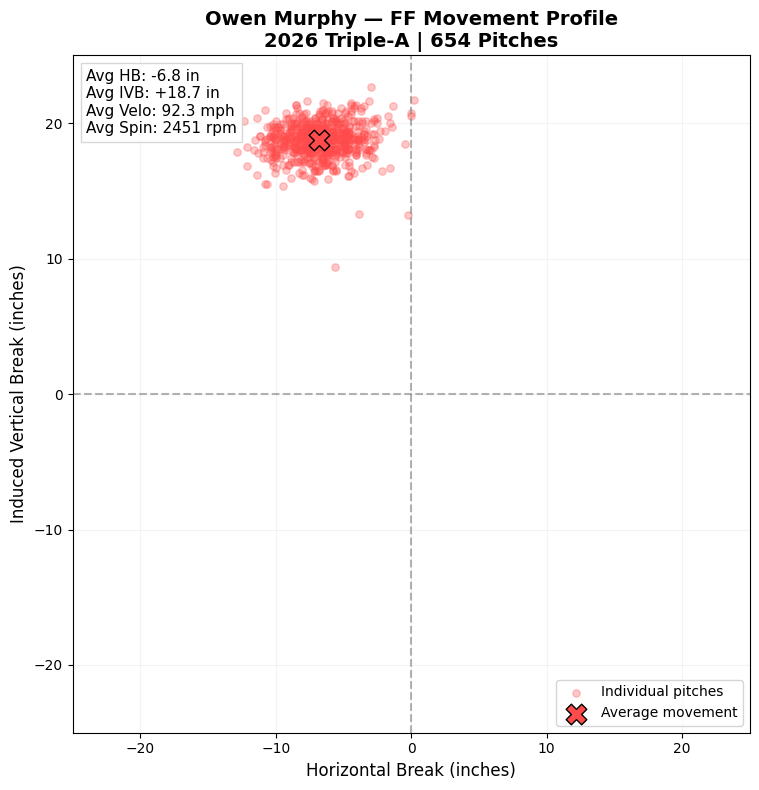

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

pitch_colors = {
    "FF": "#FF4B4B",  # Four-Seam - Red
    "SI": "#F4A261",  # Sinker - Orange
    "FC": "#C77DFF",  # Cutter - Purple
    "SL": "#F9C74F",  # Slider - Yellow
    "ST": "#90BE6D",  # Sweeper - Green
    "CU": "#277DA1",  # Curveball - Blue
    "KC": "#577590",  # Knuckle Curve - Dark Blue
    "CH": "#43AA8B",  # Changeup - Teal
    "FS": "#F3722C",  # Splitter - Dark Orange
    "SV": "#B56576",  # Slurve - Mauve
    "FO": "#8D99AE"   # Forkball - Gray
}

# Automatically retrieve color for selected pitch
pitch_color = pitch_colors.get(PITCH_TYPE, "#808080")

# ==========================================
# 4. PITCH MOVEMENT PLOT
# ==========================================

# Use selected pitch from configuration cell
movement = pitch_df.copy()

# Convert Statcast movement from feet to inches
movement["HB"] = pd.to_numeric(
    movement["pfx_x"], errors="coerce"
) * 12

movement["IVB"] = pd.to_numeric(
    movement["pfx_z"], errors="coerce"
) * 12

movement = movement.dropna(subset=["HB", "IVB"])

if movement.empty:
    print(f"No movement data available for {PITCH_TYPE}")

else:
    avg_hb = movement["HB"].mean()
    avg_ivb = movement["IVB"].mean()
    avg_velo = pd.to_numeric(
        movement["release_speed"], errors="coerce"
    ).mean()
    avg_spin = pd.to_numeric(
        movement["release_spin_rate"], errors="coerce"
    ).mean()

    fig, ax = plt.subplots(figsize=(9, 8))

    # Individual pitch movement
    ax.scatter(
        movement["HB"],
        movement["IVB"],
        color=pitch_color,
        s=28,
        alpha=0.3,
        label="Individual pitches"
    )


    # Average pitch movement
    ax.scatter(
        avg_hb,
        avg_ivb,
        color=pitch_color,
        marker="X",
        s=220,
        edgecolor="black",
        linewidth=1,
        zorder=5,
        label="Average movement"
    )

    # Reference lines
    ax.axhline(0, color="gray", linestyle="--", alpha=0.6)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.6)

    # Consistent axes for comparisons between pitch types
    ax.set_xlim(-25, 25)
    ax.set_ylim(-25, 25)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Horizontal Break (inches)", fontsize=12)
    ax.set_ylabel("Induced Vertical Break (inches)", fontsize=12)

    ax.set_title(
        f"Owen Murphy — {PITCH_TYPE} Movement Profile\n"
        f"2026 Triple-A | {len(movement)} Pitches",
        fontsize=14,
        weight="bold"
    )

    stats_text = (
        f"Avg HB: {avg_hb:+.1f} in\n"
        f"Avg IVB: {avg_ivb:+.1f} in\n"
        f"Avg Velo: {avg_velo:.1f} mph\n"
        f"Avg Spin: {avg_spin:.0f} rpm"
    )

    ax.text(
        0.02, 0.98,
        stats_text,
        transform=ax.transAxes,
        va="top",
        fontsize=11,
        bbox=dict(
            facecolor="white",
            edgecolor="lightgray",
            alpha=0.9
        )
    )

    ax.legend(loc="lower right")
    ax.grid(alpha=0.15)

    plt.tight_layout()
    plt.show()


Selected pitch: FF
Pitches with location data: 654
Swings: 324
Whiffs: 69
Tracked BIP: 117


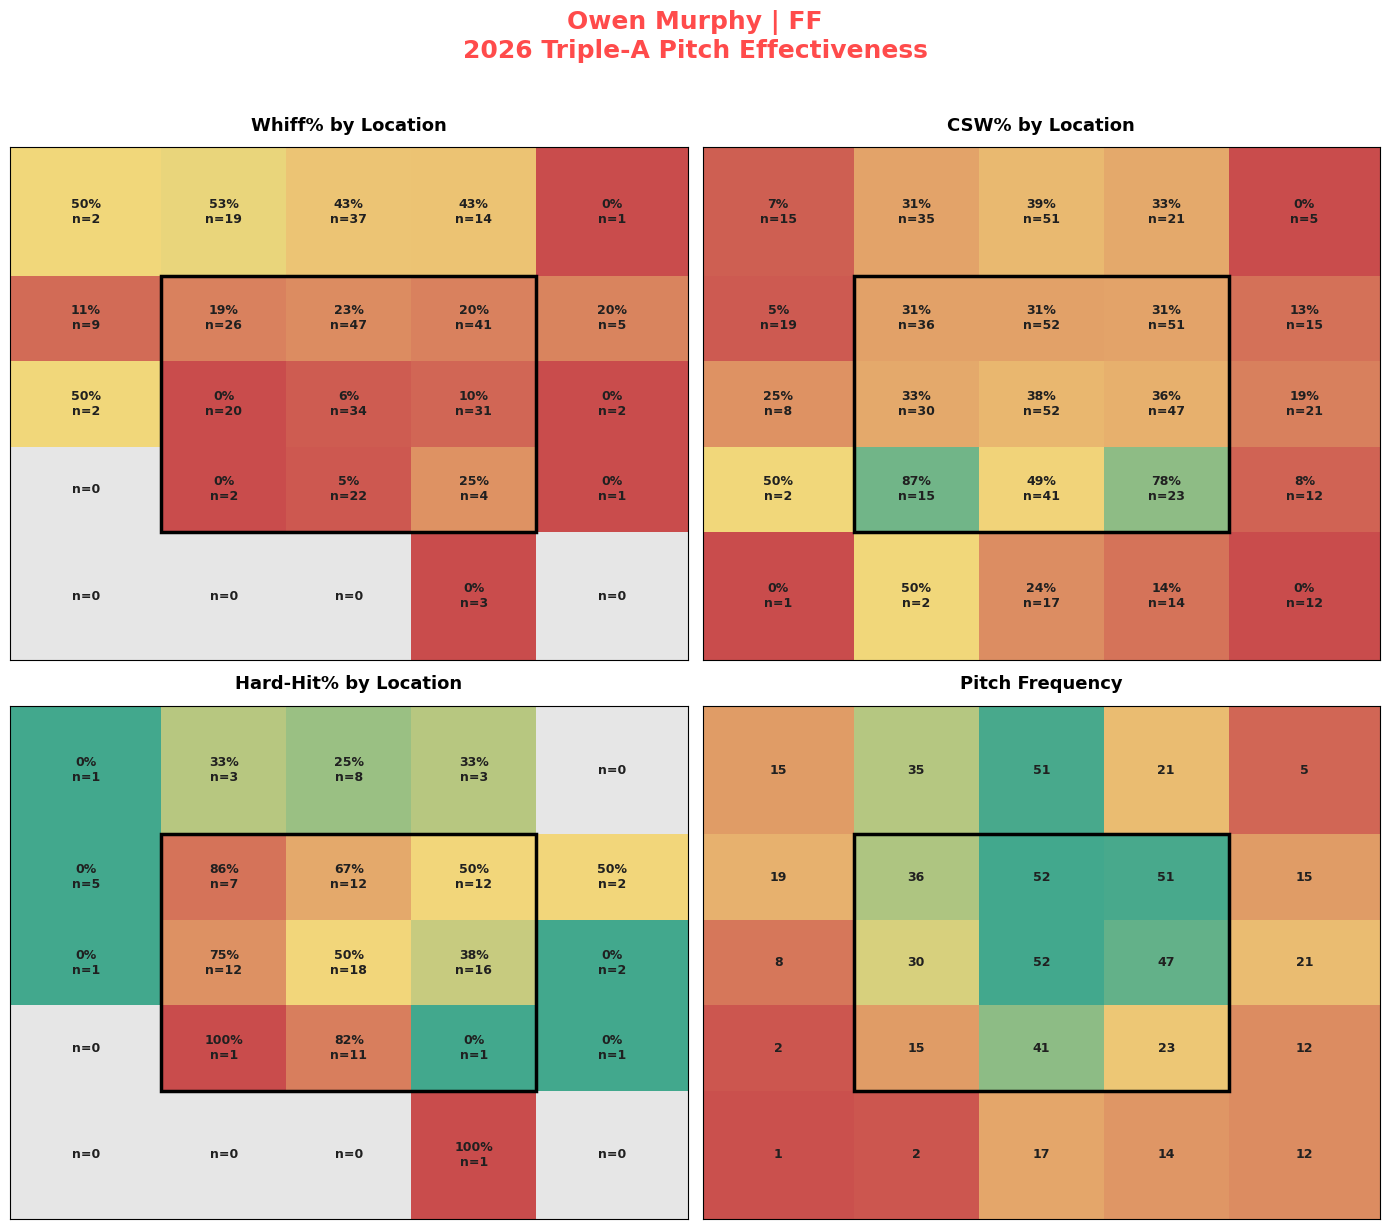

In [ ]:

# ==========================================
# 5A. PITCH EFFECTIVENESS DATA
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap

hot = pitch_df.copy()

# Ensure numeric columns
for col in [
    "plate_x", "plate_z", "sz_top", "sz_bot",
    "launch_speed"
]:
    hot[col] = pd.to_numeric(hot[col], errors="coerce")

# Normalize each batter's strike zone
zone_height = hot["sz_top"] - hot["sz_bot"]

hot["z_norm"] = np.where(
    zone_height > 0,
    (hot["plate_z"] - hot["sz_bot"]) / zone_height,
    np.nan
)

# Pitch outcome definitions
whiff_codes = [
    "swinging_strike",
    "swinging_strike_blocked",
    "missed_bunt"
]

swing_codes = whiff_codes + [
    "foul",
    "foul_tip",
    "hit_into_play",
    "foul_bunt"
]

desc = hot["description"].fillna("")

hot["swing"] = desc.isin(swing_codes)
hot["whiff"] = desc.isin(whiff_codes)
hot["called_strike"] = desc.eq("called_strike")
hot["csw"] = hot["whiff"] | hot["called_strike"]

hot["tracked_bip"] = (
    desc.eq("hit_into_play") &
    hot["launch_speed"].notna()
)

hot["hard_hit"] = (
    hot["tracked_bip"] &
    (hot["launch_speed"] >= 95)
)

hot["pitch_count"] = True

# Remove pitches without valid location data
hot = hot.dropna(subset=["plate_x", "z_norm"])

print(f"Selected pitch: {PITCH_TYPE}")
print(f"Pitches with location data: {len(hot)}")
print(f"Swings: {hot['swing'].sum()}")
print(f"Whiffs: {hot['whiff'].sum()}")
print(f"Tracked BIP: {hot['tracked_bip'].sum()}")



# ==========================================
# 5B. HOT ZONE PLOTTING FUNCTIONS
# ==========================================

# 5 columns: outside / 3 strike-zone columns / outside
X_EDGES = np.array([
    -1.5, -0.83, -0.83/3,
     0.83/3, 0.83, 1.5
])

# 5 rows: below / 3 strike-zone rows / above
Z_EDGES = np.array([
    -0.5, 0, 1/3, 2/3, 1, 1.5
])

def location_counts(data, condition):
    """Count qualifying pitches in every location cell."""

    selected = data.loc[condition]

    counts, _, _ = np.histogram2d(
        selected["plate_x"],
        selected["z_norm"],
        bins=[X_EDGES, Z_EDGES]
    )

    return counts.T


def create_hotzone(data, success, eligible,
                   min_n=5):
    """Calculate metric percentage and sample size."""

    numerator = location_counts(data, data[success])
    denominator = location_counts(data, data[eligible])

    rates = np.divide(
        numerator * 100,
        denominator,
        out=np.full_like(numerator, np.nan),
        where=denominator > 0
    )

    rates[denominator < min_n] = np.nan

    return rates, denominator


def plot_hotzone(ax, values, counts, title,
                 min_n=5, reverse=False,
                 is_count=False):

    # Red = poor for pitcher, green = good
    colors = ["#C94C4C", "#F2D77A", "#42A88D"]

    if reverse:
        colors = colors[::-1]

    cmap = LinearSegmentedColormap.from_list(
        "effectiveness", colors
    ).copy()

    cmap.set_bad("#E6E6E6")

    plotted = np.ma.masked_invalid(values)

    vmax = max(np.nanmax(values), 1) if (
        is_count and np.isfinite(values).any()
    ) else 100

    ax.pcolormesh(
        X_EDGES, Z_EDGES, plotted,
        cmap=cmap,
        vmin=0,
        vmax=vmax,
        shading="flat"
    )

    # Label cells
    for i in range(5):
        for j in range(5):

            x = (X_EDGES[j] + X_EDGES[j+1]) / 2
            y = (Z_EDGES[i] + Z_EDGES[i+1]) / 2

            n = int(counts[i, j])
            val = values[i, j]

            if is_count:
                label = str(n)
            elif np.isnan(val):
                label = f"n={n}"
            else:
                label = f"{val:.0f}%\nn={n}"

            ax.text(
                x, y, label,
                ha="center",
                va="center",
                fontsize=9,
                weight="bold",
                color="#202020"
            )

    # Actual normalized strike zone
    ax.add_patch(
        Rectangle(
            (-0.83, 0),
            1.66, 1,
            fill=False,
            edgecolor="black",
            linewidth=2.5
        )
    )

    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-0.5, 1.5)

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_title(
        title,
        fontsize=13,
        weight="bold",
        pad=12
    )

    ax.set_aspect("auto")


# ==========================================
# 5C. GENERATE PITCH HOT ZONES
# ==========================================

# Minimum sample sizes
MIN_SWINGS = 0
MIN_PITCHES = 0
MIN_BIP = 0

# 1. Whiff%
whiff, whiff_n = create_hotzone(
    hot, "whiff", "swing",
    min_n=MIN_SWINGS
)

# 2. CSW%
csw, csw_n = create_hotzone(
    hot, "csw", "pitch_count",
    min_n=MIN_PITCHES
)

# 3. Hard-Hit%
hard, hard_n = create_hotzone(
    hot, "hard_hit", "tracked_bip",
    min_n=MIN_BIP
)

# 4. Frequency
frequency = location_counts(
    hot, hot["pitch_count"]
)

# ==========================================
# DRAW FOUR CHARTS
# ==========================================

fig, axes = plt.subplots(
    2, 2, figsize=(14, 12)
)

plot_hotzone(
    axes[0, 0],
    whiff, whiff_n,
    "Whiff% by Location"
)

plot_hotzone(
    axes[0, 1],
    csw, csw_n,
    "CSW% by Location"
)

plot_hotzone(
    axes[1, 0],
    hard, hard_n,
    "Hard-Hit% by Location",
    reverse=True
)

plot_hotzone(
    axes[1, 1],
    frequency, frequency,
    "Pitch Frequency",
    is_count=True
)

fig.suptitle(
    f"Owen Murphy | {PITCH_TYPE}\n"
    f"2026 Triple-A Pitch Effectiveness",
    fontsize=18,
    fontweight="bold",
    color=pitch_color,
    y=1.02
)

plt.tight_layout()
plt.show()


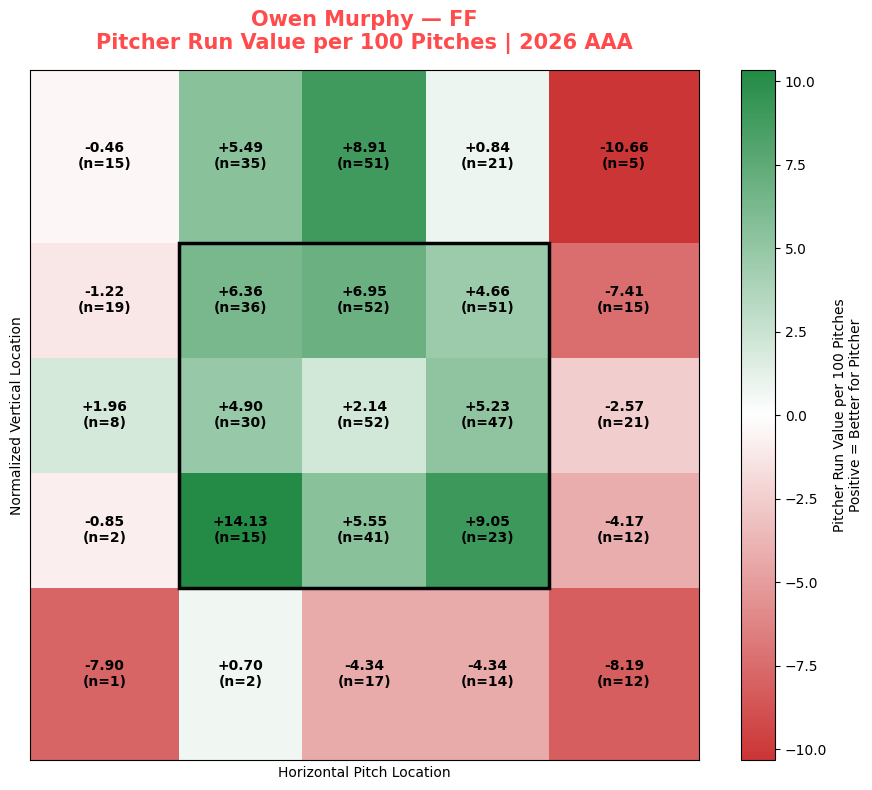


PITCH TYPE: FF
Pitches with valid location/RV: 654
Total Pitcher Run Value: +16.70
Pitcher RV per 100: +2.55
Pitches included in grid: 597
Pitches outside grid: 57

Pitcher RV by outcome:


,count,mean
events,,
double,6,-0.749
home_run,8,-1.232
strikeout,50,0.244


In [ ]:

# ==========================================
# 6. PITCHER RUN VALUE HOT ZONE
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

# ==========================================
# 1. SELECTED PITCH
# ==========================================

# Uses existing PITCH_TYPE and pitch_df variables
rv_df = pitch_df.copy()

selected_color = pitch_colors.get(PITCH_TYPE, "#333333")

# ==========================================
# 2. PREPARE DATA
# ==========================================

required_cols = [
    "plate_x",
    "plate_z",
    "sz_top",
    "sz_bot",
    "delta_pitcher_run_exp"
]

for col in required_cols:
    rv_df[col] = pd.to_numeric(
        rv_df[col], errors="coerce"
    )

# Normalize vertical location
zone_height = rv_df["sz_top"] - rv_df["sz_bot"]

rv_df["z_norm"] = np.where(
    zone_height > 0,
    (rv_df["plate_z"] - rv_df["sz_bot"]) / zone_height,
    np.nan
)

# Remove pitches missing location or pitcher RV
rv_df = rv_df.dropna(
    subset=[
        "plate_x",
        "z_norm",
        "delta_pitcher_run_exp"
    ]
)

if rv_df.empty:
    raise ValueError(
        f"No valid pitcher run value data for {PITCH_TYPE}"
    )

# ==========================================
# 3. LOCATION GRID
# ==========================================

X_EDGES = np.array([
    -1.5, -0.83, -0.83/3,
    0.83/3, 0.83, 1.5
])

Z_EDGES = np.array([
    -0.5, 0, 1/3, 2/3, 1, 1.5
])

MIN_PITCHES = 0

# Count pitches per location
counts, _, _ = np.histogram2d(
    rv_df["plate_x"],
    rv_df["z_norm"],
    bins=[X_EDGES, Z_EDGES]
)

# Sum PITCHER run value by location
rv_sum, _, _ = np.histogram2d(
    rv_df["plate_x"],
    rv_df["z_norm"],
    bins=[X_EDGES, Z_EDGES],
    weights=rv_df["delta_pitcher_run_exp"]
)

# Run value per 100 pitches
rv100 = np.divide(
    rv_sum * 100,
    counts,
    out=np.full_like(rv_sum, np.nan),
    where=counts > 0
)

# Transpose for plotting
rv100 = rv100.T
counts = counts.T

# Hide insufficient samples
rv100[counts < MIN_PITCHES] = np.nan

# ==========================================
# 4. COLOR SCALE
# ==========================================

# NEGATIVE = BAD FOR PITCHER = RED
# ZERO = NEUTRAL = WHITE
# POSITIVE = GOOD FOR PITCHER = GREEN

cmap = LinearSegmentedColormap.from_list(
    "pitcher_rv",
    ["#CB3535", "#FFFFFF", "#238B45"]
).copy()

# Gray for insufficient data
cmap.set_bad("#E0E0E0")

valid = rv100[np.isfinite(rv100)]

# Symmetric color scale centered at zero
scale = (
    max(np.percentile(np.abs(valid), 95), 0.5)
    if len(valid) else 1.0
)

norm = TwoSlopeNorm(
    vmin=-scale,
    vcenter=0,
    vmax=scale
)

# ==========================================
# 5. GENERATE HEATMAP
# ==========================================

fig, ax = plt.subplots(figsize=(9, 8))

mesh = ax.pcolormesh(
    X_EDGES,
    Z_EDGES,
    np.ma.masked_invalid(rv100),
    cmap=cmap,
    norm=norm,
    shading="flat"
)

# Cell labels
for i in range(len(Z_EDGES) - 1):
    for j in range(len(X_EDGES) - 1):

        x = (X_EDGES[j] + X_EDGES[j+1]) / 2
        y = (Z_EDGES[i] + Z_EDGES[i+1]) / 2

        n = int(counts[i, j])
        value = rv100[i, j]

        if np.isfinite(value):
            label = f"{value:+.2f}\n(n={n})"
        else:
            label = f"n={n}"

        ax.text(
            x, y, label,
            ha="center",
            va="center",
            fontsize=10,
            weight="bold",
            color="black"
        )

# Strike zone outline
ax.add_patch(
    Rectangle(
        (-0.83, 0),
        1.66, 1,
        fill=False,
        edgecolor="black",
        linewidth=2.5
    )
)

ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-0.5, 1.5)

ax.set_xticks([])
ax.set_yticks([])

ax.set_xlabel("Horizontal Pitch Location")
ax.set_ylabel("Normalized Vertical Location")

ax.set_title(
    f"Owen Murphy — {PITCH_TYPE}\n"
    f"Pitcher Run Value per 100 Pitches | 2026 AAA",
    fontsize=15,
    fontweight="bold",
    color=selected_color,
    pad=15
)

# Colorbar
cbar = plt.colorbar(mesh, ax=ax)

cbar.set_label(
    "Pitcher Run Value per 100 Pitches\n"
    "Positive = Better for Pitcher"
)

plt.tight_layout()
plt.show()

# ==========================================
# 6. OVERALL PITCHER RV SUMMARY
# ==========================================

total_rv = rv_df["delta_pitcher_run_exp"].sum()
rv_per_100 = (total_rv / len(rv_df)) * 100

print(f"\nPITCH TYPE: {PITCH_TYPE}")
print(f"Pitches with valid location/RV: {len(rv_df)}")
print(f"Total Pitcher Run Value: {total_rv:+.2f}")
print(f"Pitcher RV per 100: {rv_per_100:+.2f}")

# Pitches outside the displayed heatmap
plotted_n = int(counts.sum())
print(f"Pitches included in grid: {plotted_n}")
print(f"Pitches outside grid: {len(rv_df) - plotted_n}")

# ==========================================
# 7. VERIFY RV SIGN CONVENTION
# ==========================================

if "events" in rv_df.columns:
    check = (
        rv_df[
            rv_df["events"].isin(
                ["strikeout", "double", "home_run"]
            )
        ]
        .groupby("events")["delta_pitcher_run_exp"]
        .agg(["count", "mean"])
        .round(3)
    )

    print("\nPitcher RV by outcome:")
    display(check)


In [ ]:

# ==========================================
# PITCH USAGE % BY BATTER HANDEDNESS
# ==========================================

# Filter all pitches for selected pitcher
usage_df = df[
    pd.to_numeric(df["pitcher"], errors="coerce") == PLAYER_ID
].copy()

# Keep only LHH and RHH
usage_df = usage_df[
    usage_df["stand"].isin(["L", "R"]) &
    usage_df["pitch_type"].notna()
]

# Count pitches by pitch type and batter handedness
usage_counts = pd.crosstab(
    usage_df["pitch_type"],
    usage_df["stand"]
)

# Calculate usage % independently for each side
usage_pct = usage_counts.div(
    usage_counts.sum(axis=0), axis=1
) * 100

# Rename columns
usage_pct = usage_pct.rename(columns={
    "L": "LHH Usage %",
    "R": "RHH Usage %"
})

# Sort by overall pitch frequency
pitch_order = usage_df["pitch_type"].value_counts().index
usage_pct = usage_pct.reindex(pitch_order)

# Add totals row
usage_pct.loc["TOTAL"] = usage_pct.sum()

# Display
print(f"Pitch Usage by Batter Handedness — Player {PLAYER_ID}")
print(f"LHH Pitches: {(usage_df['stand'] == 'L').sum()}")
print(f"RHH Pitches: {(usage_df['stand'] == 'R').sum()}")

display(usage_pct.round(1))


Pitch Usage by Batter Handedness — Player 702566
LHH Pitches: 770
RHH Pitches: 750


stand,LHH Usage %,RHH Usage %
pitch_type,,
FF,43.5,42.5
SL,23.1,33.5
CH,17.4,5.7
CU,15.5,6.8
SI,0.5,11.5
TOTAL,100.0,100.0


In [ ]:
!pip -q install nbconvert

from pathlib import Path
from google.colab import files

# Find notebooks in Colab
notebooks = list(Path("/content").glob("*.ipynb"))

print("Available notebooks:")
for nb in notebooks:
    print(nb)

Available notebooks:
/content/temp_export.ipynb


In [ ]:
from pathlib import Path
from IPython.display import display
from google.colab import files

# Select your notebook
notebook_path = Path("/content/temp_export.ipynb")

# Export to HTML
!jupyter nbconvert --to html "{notebook_path}" \
    --output "Notebook_Report.html" \
    --output-dir "/content"

# Download HTML
files.download("/content/Notebook_Report.html")

[NbConvertApp] Converting notebook /content/temp_export.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).
[NbConvertApp] Writing 732890 bytes to /content/Notebook_Report.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>